# Imports

In [2]:
import os, sys
sys.path.append("D:\\DATA\\ETL_PIC\\simulation\\")
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rc_file('D:\\DATA\\ETL_PIC\\matplotlibrc.txt')
import pandas as pd

import rsoft_lib as rlib
from rsoft_lib.device_setup import SIM, WIDTH, device_paths, scan_dir, export_device

# Design device

90° crossing at 45° bend angles, without tapers

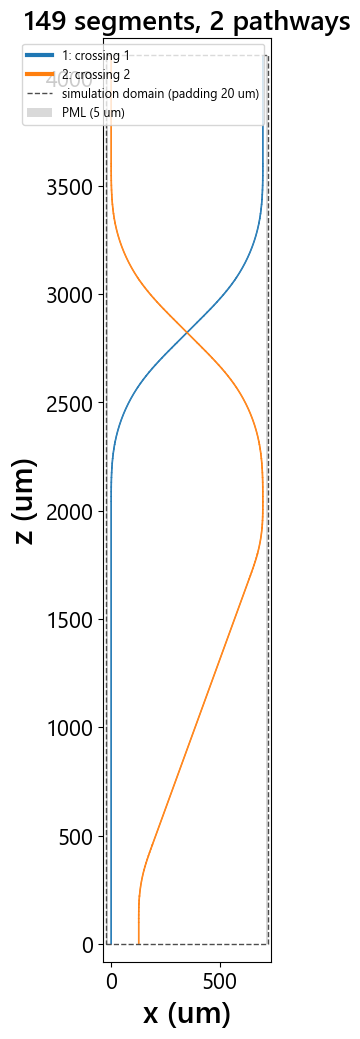

Inputs 127 μm apart; crossing 2 fans out to 700 μm (20° bends, straight 1306.0 μm); crossed at 90° at x = 350.0, z = 2822.7 μm (crossing straights 131.8 μm)
Outputs at x = 700.0 (crossing 1) and 0.0 μm (crossing 2), 700 μm apart; 4101.8 μm long; segments per pathway [57, 92]
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\A1-02b_CrossingWitness\A1-02b_CrossingWitness.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\A1-02b_CrossingWitness\A1-02b_CrossingWitness.gds


In [3]:
# Set up directories
device_name = 'A1-02b_CrossingWitness'
device_dir = f"D:\\DATA\\ETL_PIC\\simulation\\NullingPIC_Gen2_sims\\{device_name}\\"
paths = device_paths(device_dir, device_name)

# Set up parameters
input_pitch = 127.0             # centre-to-centre spacing of crossings 1 and 2 at the input facet (um)
bundle_length = 100.0          # both run straight this far, past the bundle (um)
bend_radius = 700.0             # minimum radius of every Euler bend (um)
euler_p = 0.5                   # Euler fraction (0 circular, 1 pure Euler)
fanout_angle = 20.0             # angle of crossing 2's fan-out side-step (deg, < 90)
cross_separation = 700.0        # spacing after the fan-out, before the crossing (um)
cross_angle = 45.0              # each guide turns this much toward the other: they cross at 2 * cross_angle
output_length = 500.0           # straight after the crossing to the output facet (um)

# Check that the crossing fits: each 45-degree bend alone moves its guide this far sideways
bend_shift = rlib.euler_sidestep(bend_radius, cross_angle, euler_p, straight=0.0, return_params=True)[3]["bend_offset"]
assert 2 * bend_shift <= cross_separation, (f"The crossing needs a separation of at least {2 * bend_shift:.1f} um with {cross_angle:g} deg "
                                            f"Euler bends (R_min {bend_radius:g} um, p {euler_p:g}): raise cross_separation, or lower "
                                            f"bend_radius or euler_p")

# The pieces: crossing 1 stays straight; crossing 2 alone fans out to the right to cross_separation; then both cross (crossing 1
# steps right to crossing 2's position, crossing 2 steps left to crossing 1's; the two 45-degree straights cross in the middle at 90 degrees)
x1_in, x2_in = 0.0, input_pitch
fan_step = cross_separation - input_pitch
fan2 = rlib.euler_sidestep(bend_radius, fanout_angle, euler_p, offset=fan_step, direction=1, x0=x2_in, return_params=True)
z_fan = bundle_length                                          # crossing 2's fan-out starts here
z_cross = z_fan + fan2[3]["z_length"]                          # the crossing starts here
x1_c, x2_c = x1_in, x2_in + fan_step                           # the positions before the crossing
cross1 = rlib.euler_sidestep(bend_radius, cross_angle, euler_p, offset=cross_separation, direction=1, x0=x1_c, return_params=True)
cross2 = rlib.euler_sidestep(bend_radius, cross_angle, euler_p, offset=cross_separation, direction=-1, x0=x2_c, return_params=True)
z_out = z_cross + cross1[3]["z_length"]
z_end = z_out + output_length

# Define circuit
c = rlib.Circuit(width=WIDTH, orientation="extended")

# Pathway 1, crossing 1: straight to the crossing, steps right across crossing 2, straight to the output
lead1 = c.line((x1_in, 0.0), (x1_in, z_cross))
cross1_part = c.add_path(cross1[0], cross1[1] + z_cross, cross1[2])
out1 = c.line((cross1[0][-1], z_out), (cross1[0][-1], z_end))
c.add_pathway([lead1, *cross1_part["segments"], out1], launch=True)

# Pathway 2, crossing 2: straight past the bundle, fans out to the right, steps left across crossing 1, straight to the output
lead2 = c.line((x2_in, 0.0), (x2_in, z_fan))
fan2_part = c.add_path(fan2[0], fan2[1] + z_fan, fan2[2])
cross2_part = c.add_path(cross2[0], cross2[1] + z_cross, cross2[2])
out2 = c.line((cross2[0][-1], z_out), (cross2[0][-1], z_end))
c.add_pathway([lead2, *fan2_part["segments"], *cross2_part["segments"], out2], launch=True)

# Export and visualize circuit
info = export_device(c, paths)
c.plot(labels=["crossing 1", "crossing 2"], figsize=(10, 12), equal=True)
z_x = z_cross + cross1[3]["bend_z"] + (cross_separation / 2 - cross1[3]["bend_offset"]) / np.tan(np.radians(cross_angle))
print(f"Inputs {input_pitch:g} μm apart; crossing 2 fans out to {cross_separation:g} μm ({fanout_angle:g}° bends, straight {fan2[3]['straight']:.1f} μm); "
      f"crossed at {2 * cross_angle:g}° at x = {x1_c + cross_separation / 2:.1f}, z = {z_x:.1f} μm (crossing straights {cross1[3]['straight']:.1f} μm)")
print(f"Outputs at x = {c.pathways[0].end[0]:.1f} (crossing 1) and {c.pathways[1].end[0]:.1f} μm (crossing 2), {cross_separation:g} μm apart; "
      f"{z_end:.1f} μm long; segments per pathway {[len(p.segments) for p in c.pathways]}")
print(f"Wrote {paths['ind']} and {paths['gds']}")

90° crossing at 45° bend angle, tapering down in the region of the crossing

D:\DATA\ETL_PIC\simulation\rsoft_lib\circuit.py:502: UserWarning: A width change on an arc is written as a linear taper along the arc; how RSoft interpolates along an arc has not been checked.
  warnings.warn("A width change on an arc is written as a linear taper along the arc; how RSoft interpolates along an arc "


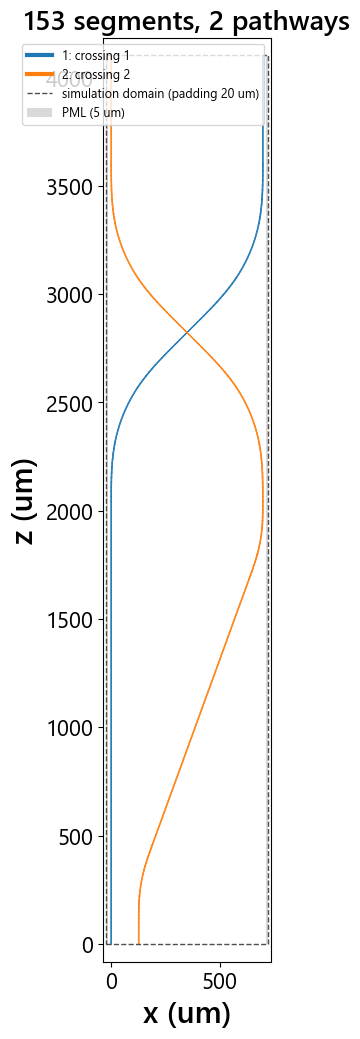

Inputs 127 μm apart; crossing 2 fans out to 700 μm (20° bends, straight 1306.0 μm); crossed at 90° at x = 350.0, z = 2822.7 μm (crossing straights 131.8 μm)
Outputs at x = 700.0 (crossing 1) and 0.0 μm (crossing 2), 700 μm apart; 4101.8 μm long; segments per pathway [59, 94]
Width at the crossing 2.4 μm over 100 μm, 250 μm raised-cosine tapers on each side (followed to 4.7 nm)
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\A1-02b_CrossingWitness\A1-02b_CrossingWitness_tapered.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\A1-02b_CrossingWitness\A1-02b_CrossingWitness_tapered.gds


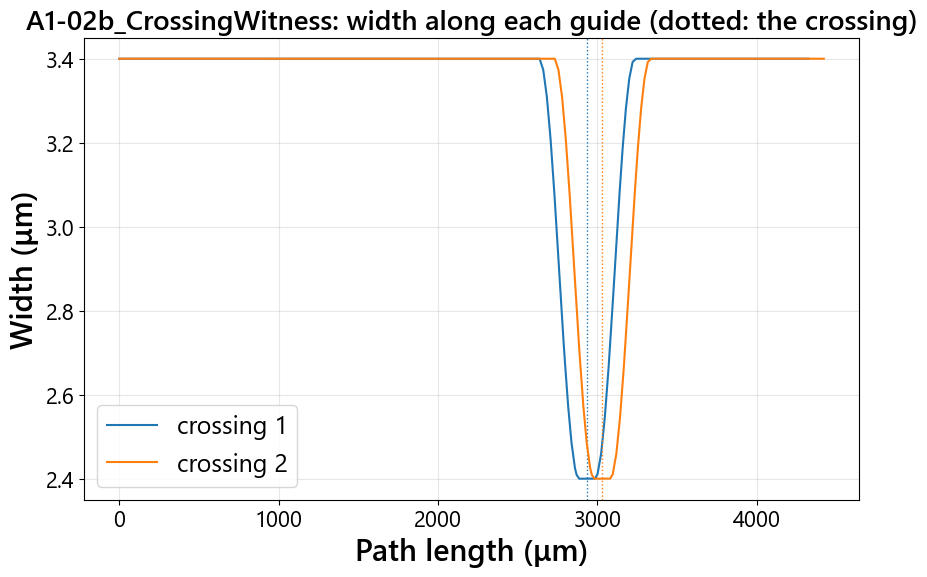

In [4]:
# Set up directories
device_name = 'A1-02b_CrossingWitness'
device_dir = f"D:\\DATA\\ETL_PIC\\simulation\\NullingPIC_Gen2_sims\\{device_name}\\"
paths = device_paths(device_dir, device_name+"_tapered")

# Set up parameters
input_pitch = 127.0             # centre-to-centre spacing of crossings 1 and 2 at the input facet (um)
bundle_length = 100.0          # both run straight this far, past the bundle (um)
bend_radius = 700.0             # minimum radius of every Euler bend (um)
euler_p = 0.5                   # Euler fraction (0 circular, 1 pure Euler)
fanout_angle = 20.0             # angle of crossing 2's fan-out side-step (deg, < 90)
cross_separation = 700.0        # spacing after the fan-out, before the crossing (um)
cross_angle = 45.0              # each guide turns this much toward the other: they cross at 2 * cross_angle
output_length = 500.0           # straight after the crossing to the output facet (um)
narrow_width = 2.4              # width at the crossing (um)
narrow_length = 100.0           # length at narrow_width, centred on the crossing (um)
taper_length = 250.0            # raised-cosine taper from WIDTH to narrow_width before it, and back after it (um)

# Check that the crossing fits: each 45-degree bend alone moves its guide this far sideways
bend_shift = rlib.euler_sidestep(bend_radius, cross_angle, euler_p, straight=0.0, return_params=True)[3]["bend_offset"]
assert 2 * bend_shift <= cross_separation, (f"The crossing needs a separation of at least {2 * bend_shift:.1f} um with {cross_angle:g} deg "
                                            f"Euler bends (R_min {bend_radius:g} um, p {euler_p:g}): raise cross_separation, or lower "
                                            f"bend_radius or euler_p")

# The pieces: crossing 1 stays straight; crossing 2 alone fans out to the right to cross_separation; then both cross (crossing 1
# steps right to crossing 2's position, crossing 2 steps left to crossing 1's; the two 45-degree straights cross in the middle at 90 degrees)
x1_in, x2_in = 0.0, input_pitch
fan_step = cross_separation - input_pitch
fan2 = rlib.euler_sidestep(bend_radius, fanout_angle, euler_p, offset=fan_step, direction=1, x0=x2_in, return_params=True)
z_fan = bundle_length                                          # crossing 2's fan-out starts here
z_cross = z_fan + fan2[3]["z_length"]                          # the crossing starts here
x1_c, x2_c = x1_in, x2_in + fan_step                           # the positions before the crossing
cross1 = rlib.euler_sidestep(bend_radius, cross_angle, euler_p, offset=cross_separation, direction=1, x0=x1_c, return_params=True)
cross2 = rlib.euler_sidestep(bend_radius, cross_angle, euler_p, offset=cross_separation, direction=-1, x0=x2_c, return_params=True)
z_out = z_cross + cross1[3]["z_length"]
z_end = z_out + output_length

# Width along each crossing side-step, as a function of the path length s from its start: the two side-steps are mirror images
# with identical bends, so each guide reaches the crossing halfway along its side-step
s_cross = cross1[3]["path_length"] / 2
cross_width = rlib.cosine_tapers((s_cross - narrow_length / 2 - taper_length, s_cross - narrow_length / 2, narrow_width),
                                 (s_cross + narrow_length / 2, s_cross + narrow_length / 2 + taper_length, WIDTH), width=WIDTH)

# Define circuit
c = rlib.Circuit(width=WIDTH, orientation="extended")

# Pathway 1, crossing 1: straight to the crossing, steps right across crossing 2 (narrowing at the crossing), straight to the output
lead1 = c.line((x1_in, 0.0), (x1_in, z_cross))
cross1_part = c.add_path(cross1[0], cross1[1] + z_cross, cross1[2], width=cross_width)
out1 = c.line((cross1[0][-1], z_out), (cross1[0][-1], z_end))
c.add_pathway([lead1, *cross1_part["segments"], out1], launch=True)

# Pathway 2, crossing 2: straight past the bundle, fans out to the right, steps left across crossing 1 (narrowing at the crossing),
# straight to the output
lead2 = c.line((x2_in, 0.0), (x2_in, z_fan))
fan2_part = c.add_path(fan2[0], fan2[1] + z_fan, fan2[2])
cross2_part = c.add_path(cross2[0], cross2[1] + z_cross, cross2[2], width=cross_width)
out2 = c.line((cross2[0][-1], z_out), (cross2[0][-1], z_end))
c.add_pathway([lead2, *fan2_part["segments"], *cross2_part["segments"], out2], launch=True)

# Export and visualize circuit
info = export_device(c, paths)
c.plot(labels=["crossing 1", "crossing 2"], figsize=(10, 12), equal=True)
z_x = z_cross + cross1[3]["bend_z"] + (cross_separation / 2 - cross1[3]["bend_offset"]) / np.tan(np.radians(cross_angle))
print(f"Inputs {input_pitch:g} μm apart; crossing 2 fans out to {cross_separation:g} μm ({fanout_angle:g}° bends, straight {fan2[3]['straight']:.1f} μm); "
      f"crossed at {2 * cross_angle:g}° at x = {x1_c + cross_separation / 2:.1f}, z = {z_x:.1f} μm (crossing straights {cross1[3]['straight']:.1f} μm)")
print(f"Outputs at x = {c.pathways[0].end[0]:.1f} (crossing 1) and {c.pathways[1].end[0]:.1f} μm (crossing 2), {cross_separation:g} μm apart; "
      f"{z_end:.1f} μm long; segments per pathway {[len(p.segments) for p in c.pathways]}")
print(f"Width at the crossing {narrow_width:g} μm over {narrow_length:g} μm, {taper_length:g} μm raised-cosine tapers on each side "
      f"(followed to {max(cross1_part['max_width_error'], cross2_part['max_width_error']) * 1e3:.1f} nm)")
print(f"Wrote {paths['ind']} and {paths['gds']}")

# Width along each pathway as a function of path length, from the circuit's segments (as written to the .ind)
plt.figure(figsize=(10, 6))
for k, label in ((1, "crossing 1"), (2, "crossing 2")):
    s_end, end, S, W = 0.0, None, [], []
    for seg in c.pathway_segments(k):
        ctr, w, _ = c._outline(seg, 400)                        # centre line and width along the segment
        if end is not None and np.hypot(*(ctr[-1] - end)) < np.hypot(*(ctr[0] - end)):
            ctr, w = ctr[::-1], w[::-1]                         # a segment written backward: follow the route
        ds = np.r_[0, np.cumsum(np.hypot(*np.diff(ctr, axis=0).T))]
        S.append(s_end + ds)
        W.append(w)
        s_end, end = s_end + ds[-1], ctr[-1]
    line, = plt.plot(np.concatenate(S), np.concatenate(W), label=label)
    # where this guide crosses the other: the start of its crossing side-step plus s_cross
    s_start = c.path_length(c.pathway(k).segments[:1]) if k == 1 else c.path_length([lead2, *fan2_part["segments"]])
    plt.axvline(s_start + s_cross, color=line.get_color(), ls=":", lw=1)
plt.xlabel("Path length (μm)")
plt.ylabel("Width (μm)")
plt.title(f"{device_name}: width along each guide (dotted: the crossing)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()